In [1]:
# ============================================================
# MOD-07 — Imputación y Control de Calidad
# Proyecto: Impacto Variabilidad Climática en Producción Arrocera
# Versión  : 1.0
# Entrada  : data/master/A1_DF_Consolidado.parquet  (MOD-06)
# Salida   : data/master/A2_DF_Imputado.parquet / .xlsx
# ============================================================
# Métodos de imputación aplicados:
#   1. KNN  (k=5, por departamento)  — variables con <50% nulos
#   2. Mediana global                — respaldo cuando KNN falla
#   3. Eliminación de filas          — variables con >80% nulos
#   Los Ind_lluvia (prec_*) se EXCLUYEN completamente (100% nulos)
# ============================================================
!pip install openpyxl pyarrow scikit-learn -q

import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.impute import KNNImputer
import pyarrow.parquet as pq
warnings.filterwarnings('ignore')

print('✅ Librerías cargadas')


✅ Librerías cargadas


In [2]:
# ============================================================
# CONFIGURACIÓN DE RUTAS — MOD-07
# ============================================================

from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
    print('✅ Google Drive montado')
else:
    print('✅ Google Drive ya montado')

# ── Detección automática de RUTA_BASE ────────────────────────
ARCHIVO_ANCLA = 'A1_DF_Consolidado.parquet'
RUTA_BASE     = None

print()
print('🔍 Buscando carpeta del proyecto...')
for dirpath, dirnames, filenames in os.walk('/content/drive/MyDrive'):
    depth = dirpath.replace('/content/drive/MyDrive', '').count(os.sep)
    if depth > 5:
        dirnames.clear()
        continue
    if ARCHIVO_ANCLA in filenames:
        candidate = os.path.dirname(os.path.dirname(dirpath))
        if os.path.isdir(os.path.join(candidate, 'data', 'master')):
            RUTA_BASE = candidate
            print(f'   ✅ Proyecto en: {RUTA_BASE}')
            break

if RUTA_BASE is None:
    RUTA_BASE = '/content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II'
    print(f'   ⚠️  No encontrado. Usando ruta manual: {RUTA_BASE}')

RUTA_MASTER    = os.path.join(RUTA_BASE, 'data', 'master')
RUTA_PROCESSED = os.path.join(RUTA_BASE, 'data', 'processed')
os.makedirs(RUTA_MASTER, exist_ok=True)

# ── Archivos de ENTRADA / SALIDA ─────────────────────────────
ENTRADA_CONSOLIDADO = os.path.join(RUTA_MASTER, 'A1_DF_Consolidado.parquet')
SALIDA_IMPUTADO     = os.path.join(RUTA_MASTER, 'A2_DF_Imputado.parquet')
SALIDA_IMPUTADO_XLS = os.path.join(RUTA_MASTER, 'A2_DF_Imputado.xlsx')
SALIDA_REPORTE_XLS  = os.path.join(RUTA_MASTER, 'A2_Reporte_Imputacion.xlsx')

# ── Parámetros de imputación ─────────────────────────────────
KNN_K             = 5      # vecinos para KNNImputer
UMBRAL_EXCLUIR    = 0.80   # excluir columna si >80% nulos
UMBRAL_KNN        = 0.50   # usar KNN si <=50% nulos; mediana si >50%
COLS_JOIN         = ['Periodo', 'Departamento', 'Municipio']

# ── Bloques climáticos (Ind_lluvia EXCLUIDO — 100% nulos) ────
BLOQUES = {
    'Temperatura'  : 'temperatura_',
    'Precipitacion': 'precipitacion_',
    'Radiacion'    : 'radiacion_',
    'Humedad'      : 'hr_',
}
# Prefijo de indicadores de lluvia — se eliminan del dataset
PREFIJO_EXCLUIR = 'prec_'

print()
print('📂 Rutas:')
print(f'   Master    → {RUTA_MASTER}')
print(f'   Entrada   → {os.path.basename(ENTRADA_CONSOLIDADO)}')
existe = os.path.exists(ENTRADA_CONSOLIDADO)
if not existe:
    raise FileNotFoundError(
        f'No se encontró {ENTRADA_CONSOLIDADO}.\n'
        'Ejecuta MOD-06 antes de continuar.'
    )
print(f'   ✅ A1_DF_Consolidado.parquet encontrado')
print()
print('⚙️  Parámetros de imputación:')
print(f'   KNN K             : {KNN_K} vecinos')
print(f'   Umbral KNN        : columnas con <= {UMBRAL_KNN*100:.0f}% nulos')
print(f'   Umbral excluir    : columnas con >  {UMBRAL_EXCLUIR*100:.0f}% nulos')
print(f'   Ind_lluvia (prec_): EXCLUIDOS (100% nulos)')


Mounted at /content/drive
✅ Google Drive montado

🔍 Buscando carpeta del proyecto...
   ✅ Proyecto en: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II

📂 Rutas:
   Master    → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master
   Entrada   → A1_DF_Consolidado.parquet
   ✅ A1_DF_Consolidado.parquet encontrado

⚙️  Parámetros de imputación:
   KNN K             : 5 vecinos
   Umbral KNN        : columnas con <= 50% nulos
   Umbral excluir    : columnas con >  80% nulos
   Ind_lluvia (prec_): EXCLUIDOS (100% nulos)


In [3]:
# ============================================================
# FUNCIONES UTILITARIAS — MOD-07
# ============================================================

def reporte_nulos(df, cols, titulo=''):
    """Tabla de nulos por columna para un subconjunto."""
    nulos = df[cols].isna().sum()
    pct   = nulos / len(df) * 100
    tbl   = pd.DataFrame({'columna': cols,
                          'nulos': nulos.values,
                          'pct_nulos': pct.values.round(2)})
    tbl = tbl[tbl['nulos'] > 0].sort_values('pct_nulos', ascending=False)
    if titulo:
        print(f'\n{titulo}')
    return tbl


def imputar_bloque_knn(df, cols, k=5, grupo_col='Departamento'):
    """
    KNN por grupo (departamento).

    Método KNN (K-Nearest Neighbors Imputation):
    ─────────────────────────────────────────────
    Para cada fila con valor faltante, busca las k filas más
    similares (vecinas) usando distancia euclidiana sobre las
    columnas del mismo bloque. Imputa con el promedio ponderado
    de los k vecinos. Se aplica POR DEPARTAMENTO para garantizar
    que los vecinos sean climatológicamente comparables
    (misma región geográfica).

    Ventaja   : preserva la estructura de correlación entre meses.
    Limitación: requiere al menos k filas completas por grupo.
    Respaldo  : si un grupo tiene < k filas válidas, usa mediana global.

    Retorna df con las cols imputadas y un dict de trazabilidad.
    """
    df_out    = df.copy()
    traza     = {}   # {col: {'metodo': ..., 'n_imputados': ...}}
    grupos    = df[grupo_col].unique() if grupo_col in df.columns else ['_todo']

    for col in cols:
        n_nulos_orig = df_out[col].isna().sum()
        if n_nulos_orig == 0:
            traza[col] = {'metodo': 'sin_imputacion', 'n_imputados': 0}
            continue

        imputados_total = 0

        for grp in grupos:
            mask_grp = (df_out[grupo_col] == grp) if grupo_col in df_out.columns                        else pd.Series([True]*len(df_out), index=df_out.index)
            idx_grp  = df_out[mask_grp].index
            sub      = df_out.loc[idx_grp, cols].copy()

            n_nulos_grp = sub[col].isna().sum()
            if n_nulos_grp == 0:
                continue

            n_validos = sub[col].notna().sum()

            if n_validos >= k:
                # KNN dentro del grupo
                imputer = KNNImputer(n_neighbors=min(k, n_validos),
                                     weights='distance')
                try:
                    sub_imp = imputer.fit_transform(sub.values)
                    df_out.loc[idx_grp, cols] = sub_imp
                    imputados_total += n_nulos_grp
                except Exception:
                    # Fallback mediana del grupo
                    mediana_grp = df_out.loc[idx_grp, col].median()
                    if pd.isna(mediana_grp):
                        mediana_grp = df_out[col].median()
                    df_out.loc[idx_grp & df_out[col].isna(), col] = mediana_grp
                    imputados_total += n_nulos_grp
            else:
                # Mediana del grupo (pocos datos para KNN)
                mediana_grp = df_out.loc[idx_grp, col].median()
                if pd.isna(mediana_grp):
                    mediana_grp = df_out[col].median()
                if not pd.isna(mediana_grp):
                    mask_nan = mask_grp & df_out[col].isna()
                    df_out.loc[mask_nan, col] = mediana_grp
                    imputados_total += mask_nan.sum()

        # Nulos residuales → mediana global
        nulos_res = df_out[col].isna().sum()
        metodo    = 'KNN_depto'
        if nulos_res > 0:
            mediana_global = df_out[col].median()
            if not pd.isna(mediana_global):
                df_out[col].fillna(mediana_global, inplace=True)
                metodo = 'KNN_depto+mediana_global'
                imputados_total += nulos_res

        traza[col] = {'metodo': metodo, 'n_imputados': imputados_total}

    return df_out, traza


def imputar_mediana_global(df, cols):
    """
    Mediana global por columna.

    Método Mediana Global:
    ──────────────────────
    Imputa cada valor faltante con la mediana de todos los
    valores disponibles de esa columna (sin considerar grupo).
    Se aplica a columnas con >50% de nulos donde KNN no es
    confiable, o como último recurso tras KNN.

    Ventaja   : robusto ante valores extremos (vs media).
    Limitación: no preserva correlaciones entre columnas.

    Retorna df con cols imputadas y dict de trazabilidad.
    """
    df_out = df.copy()
    traza  = {}
    for col in cols:
        n_nulos = df_out[col].isna().sum()
        if n_nulos == 0:
            traza[col] = {'metodo': 'sin_imputacion', 'n_imputados': 0}
            continue
        mediana = df_out[col].median()
        if pd.isna(mediana):
            traza[col] = {'metodo': 'sin_datos', 'n_imputados': 0}
            continue
        df_out[col].fillna(mediana, inplace=True)
        traza[col] = {'metodo': 'mediana_global', 'n_imputados': n_nulos}
    return df_out, traza


def construir_reporte_imputacion(traza_dict, df_antes, df_despues, cols_excluidas):
    """Consolida trazabilidad de imputación en un DataFrame."""
    rows = []
    for col, info in traza_dict.items():
        n_orig   = df_antes[col].isna().sum() if col in df_antes.columns else 0
        n_final  = df_despues[col].isna().sum() if col in df_despues.columns else 0
        pct_orig = n_orig / len(df_antes) * 100 if len(df_antes) else 0
        rows.append({
            'columna'    : col,
            'nulos_orig' : n_orig,
            'pct_orig'   : round(pct_orig, 2),
            'nulos_final': n_final,
            'metodo'     : info.get('metodo', ''),
            'n_imputados': info.get('n_imputados', 0),
        })
    for col in cols_excluidas:
        rows.append({
            'columna'    : col,
            'nulos_orig' : df_antes[col].isna().sum() if col in df_antes.columns else 0,
            'pct_orig'   : 100.0,
            'nulos_final': None,
            'metodo'     : 'EXCLUIDA (100% nulos)',
            'n_imputados': 0,
        })
    return pd.DataFrame(rows).sort_values('pct_orig', ascending=False)


print('✅ Funciones utilitarias cargadas')
print()
print('Métodos disponibles:')
print('  • imputar_bloque_knn()      — KNN por departamento (k=5)')
print('  • imputar_mediana_global()  — Mediana global por columna')
print('  • construir_reporte_imputacion() — Trazabilidad completa')


✅ Funciones utilitarias cargadas

Métodos disponibles:
  • imputar_bloque_knn()      — KNN por departamento (k=5)
  • imputar_mediana_global()  — Mediana global por columna
  • construir_reporte_imputacion() — Trazabilidad completa


In [4]:
# ============================================================
# CARGAR A1_DF_Consolidado
# ============================================================

print('📥 Cargando A1_DF_Consolidado.parquet...')
df_raw = pd.read_parquet(ENTRADA_CONSOLIDADO)

# Normalizar texto en columnas ID
for col in ['Periodo', 'Departamento', 'Municipio']:
    if col in df_raw.columns:
        df_raw[col] = df_raw[col].astype(str).str.strip().str.upper()

print(f'   Shape       : {df_raw.shape[0]:,} filas × {df_raw.shape[1]} cols')
print(f'   Periodos    : {sorted(df_raw["Periodo"].unique())}')
print(f'   Departamentos: {df_raw["Departamento"].nunique()}')
print(f'   Municipios  : {df_raw["Municipio"].nunique()}')
print()

# ── Identificar bloques de columnas ──────────────────────────
COLS_ID     = [c for c in df_raw.columns
               if c in ['Periodo','Departamento','Municipio',
                        'Año','Semestre','Cuadrante','Cultivo',
                        'Desagregación cultivo','Es_Top500']]
COLS_TARGET = [c for c in df_raw.columns
               if any(k in c for k in ['Producción','Rendimiento',
                                        'Área','Produccion','Area'])]

# Columnas climáticas por bloque (excluir prec_ desde el inicio)
COLS_TEMP   = sorted([c for c in df_raw.columns if c.startswith('temperatura_')])
COLS_PREC   = sorted([c for c in df_raw.columns if c.startswith('precipitacion_')])
COLS_RAD    = sorted([c for c in df_raw.columns if c.startswith('radiacion_')])
COLS_HR     = sorted([c for c in df_raw.columns if c.startswith('hr_')])
COLS_LLUVIA = sorted([c for c in df_raw.columns if c.startswith('prec_')])

COLS_CLIMA_OK = COLS_TEMP + COLS_PREC + COLS_RAD + COLS_HR
# Ind_lluvia excluidos (100% nulos confirmados en MOD-06)
COLS_EXCLUIDAS = COLS_LLUVIA

print('📋 Columnas por bloque:')
print(f'   Identificadores + meta : {len(COLS_ID)}')
print(f'   Variables objetivo     : {len(COLS_TARGET)}  {COLS_TARGET}')
print(f'   Temperatura            : {len(COLS_TEMP)}  {COLS_TEMP[:3]}...')
print(f'   Precipitación          : {len(COLS_PREC)}  {COLS_PREC[:3]}...')
print(f'   Radiación              : {len(COLS_RAD)}  {COLS_RAD[:3]}...')
print(f'   Humedad relativa       : {len(COLS_HR)}  {COLS_HR[:3]}...')
print(f'   Ind_lluvia (EXCLUIR)   : {len(COLS_LLUVIA)}  ← 100% nulos')
print()

# ── Diagnóstico de nulos ANTES ────────────────────────────────
print('='*62)
print('  DIAGNÓSTICO DE NULOS — ANTES DE IMPUTACIÓN')
print('='*62)
for nombre_b, cols_b in [
    ('Temperatura',   COLS_TEMP),
    ('Precipitación', COLS_PREC),
    ('Radiación',     COLS_RAD),
    ('Humedad rel.',  COLS_HR),
    ('Ind_lluvia',    COLS_LLUVIA),
]:
    if not cols_b:
        continue
    pct_med = df_raw[cols_b].isna().mean().mul(100).mean()
    emoji = '✅' if pct_med < 10 else ('⚠️ ' if pct_med < 50 else '❌')
    excl  = ' ← EXCLUIDO' if cols_b == COLS_LLUVIA else ''
    print(f'   {emoji} {nombre_b:<18}: {pct_med:6.1f}% nulos promedio{excl}')
print()

# Tabla detallada de nulos
df_nulos_orig = reporte_nulos(df_raw, COLS_CLIMA_OK, 'Detalle nulos (columnas con > 0 nulos):')
display(df_nulos_orig.head(20))


📥 Cargando A1_DF_Consolidado.parquet...
   Shape       : 173 filas × 144 cols
   Periodos    : ['2020A', '2020B', '2021A', '2021B', '2022A', '2022B', '2023A', '2023B', '2024A', '2024B']
   Departamentos: 10
   Municipios  : 32

📋 Columnas por bloque:
   Identificadores + meta : 7
   Variables objetivo     : 4  ['Área sembrada (ha)', 'Área cosechada (ha)', 'Producción (t)', 'Rendimiento (t/ha)']
   Temperatura            : 24  ['temperatura_maxima_m1', 'temperatura_maxima_m2', 'temperatura_maxima_m3']...
   Precipitación          : 30  ['precipitacion_maxima_m1', 'precipitacion_maxima_m2', 'precipitacion_maxima_m3']...
   Radiación              : 12  ['radiacion_allsky_m1', 'radiacion_allsky_m2', 'radiacion_allsky_m3']...
   Humedad relativa       : 36  ['hr_dias_riesgo_alto_m1', 'hr_dias_riesgo_alto_m2', 'hr_dias_riesgo_alto_m3']...
   Ind_lluvia (EXCLUIR)   : 18  ← 100% nulos

  DIAGNÓSTICO DE NULOS — ANTES DE IMPUTACIÓN
   ⚠️  Temperatura       :   23.9% nulos promedio
   ⚠️  Precipi

,columna,nulos,pct_nulos
96,hr_std_m1,49,28.32
101,hr_std_m6,48,27.75
100,hr_std_m5,48,27.75
70,hr_dias_riesgo_alto_m5,48,27.75
82,hr_maxima_m5,48,27.75
76,hr_dias_riesgo_bajo_m5,48,27.75
88,hr_media_m5,48,27.75
94,hr_minima_m5,48,27.75
18,temperatura_std_m1,47,27.17
66,hr_dias_riesgo_alto_m1,47,27.17


In [5]:
# ============================================================
# PASO 1 — ELIMINAR IND_LLUVIA (100% nulos) Y PREPARAR df_work
# ============================================================

print('🗑️  Eliminando columnas Ind_lluvia (100% nulos)...')
print(f'   Columnas eliminadas: {COLS_EXCLUIDAS}')

df_work = df_raw.drop(columns=COLS_EXCLUIDAS, errors='ignore').copy()

# ── Clasificar columnas climáticas según % nulos ─────────────
print()
print('📊 Clasificación de columnas por nivel de nulos:')
print(f'   {"Columna":<35}  {"% Nulos":>8}  Método asignado')
print(f'   {"-"*65}')

COLS_KNN      = []   # <= 50% nulos → KNN por departamento
COLS_MEDIANA  = []   # >50% y <=80% nulos → mediana global
COLS_ELIMINAR = []   # >80% nulos → eliminar

for col in COLS_CLIMA_OK:
    if col not in df_work.columns:
        continue
    pct = df_work[col].isna().mean() * 100
    if pct == 0:
        metodo = 'sin_imputacion'
        COLS_KNN.append(col)
    elif pct <= UMBRAL_KNN * 100:
        metodo = 'KNN_depto'
        COLS_KNN.append(col)
    elif pct <= UMBRAL_EXCLUIR * 100:
        metodo = 'mediana_global'
        COLS_MEDIANA.append(col)
    else:
        metodo = 'ELIMINAR'
        COLS_ELIMINAR.append(col)
    emoji = '🟢' if pct == 0 else ('🟡' if pct <= 50 else ('🟠' if pct <= 80 else '🔴'))
    print(f'   {emoji} {col:<35}  {pct:>7.1f}%  {metodo}')

print()
print(f'   Resumen:')
print(f'   🟢 KNN (<=50% nulos)     : {len(COLS_KNN)} columnas')
print(f'   🟠 Mediana (50-80% nulos): {len(COLS_MEDIANA)} columnas')
print(f'   🔴 Eliminar (>80% nulos) : {len(COLS_ELIMINAR)} columnas')

if COLS_ELIMINAR:
    print()
    print(f'   Columnas a eliminar por >80% nulos:')
    for c in COLS_ELIMINAR:
        pct = df_work[c].isna().mean()*100
        print(f'     - {c}  ({pct:.1f}%)')
    df_work.drop(columns=COLS_ELIMINAR, inplace=True)
    print(f'   ✅ Eliminadas del dataset')


🗑️  Eliminando columnas Ind_lluvia (100% nulos)...
   Columnas eliminadas: ['prec_dias_lluvia_m1', 'prec_dias_lluvia_m2', 'prec_dias_lluvia_m3', 'prec_dias_lluvia_m4', 'prec_dias_lluvia_m5', 'prec_dias_lluvia_m6', 'prec_minima_m1', 'prec_minima_m2', 'prec_minima_m3', 'prec_minima_m4', 'prec_minima_m5', 'prec_minima_m6', 'prec_pct_dias_lluvia_m1', 'prec_pct_dias_lluvia_m2', 'prec_pct_dias_lluvia_m3', 'prec_pct_dias_lluvia_m4', 'prec_pct_dias_lluvia_m5', 'prec_pct_dias_lluvia_m6']

📊 Clasificación de columnas por nivel de nulos:
   Columna                               % Nulos  Método asignado
   -----------------------------------------------------------------
   🟡 temperatura_maxima_m1                   26.6%  KNN_depto
   🟡 temperatura_maxima_m2                   22.0%  KNN_depto
   🟡 temperatura_maxima_m3                   21.4%  KNN_depto
   🟡 temperatura_maxima_m4                   21.4%  KNN_depto
   🟡 temperatura_maxima_m5                   26.0%  KNN_depto
   🟡 temperatura_maxim

In [6]:
# ============================================================
# PASO 2 — IMPUTACIÓN KNN (columnas con <= 50% nulos)
#
# KNN IMPUTER — Explicación del método:
# ─────────────────────────────────────
# KNNImputer (scikit-learn) reemplaza cada valor faltante con
# el promedio ponderado de los K vecinos más cercanos.
#
# La "cercanía" se mide con distancia euclidiana sobre todas
# las columnas del bloque (ej. temperatura_media_m1..m6).
# Los vecinos más cercanos reciben mayor peso (weights=distance).
#
# Estrategia REGIONAL:
#   Se aplica DENTRO de cada Departamento para que los vecinos
#   compartan condiciones climáticas similares. Si un departamento
#   tiene < K filas válidas, se usa la mediana del departamento
#   como respaldo. Si tampoco hay mediana departamental,
#   se usa la mediana global de toda Colombia.
#
# Elección de K=5:
#   Valor estándar para datasets de tamaño medio. Suficientemente
#   robusto para capturar tendencias sin sobre-suavizar.
# ============================================================

import time
t0 = time.time()

# Separar columnas con nulos reales de las completas
COLS_KNN_CON_NULOS = [c for c in COLS_KNN
                       if c in df_work.columns and df_work[c].isna().sum() > 0]
COLS_KNN_SIN_NULOS = [c for c in COLS_KNN
                       if c in df_work.columns and df_work[c].isna().sum() == 0]

print('🔧 Imputación KNN por departamento')
print(f'   Columnas a imputar : {len(COLS_KNN_CON_NULOS)}')
print(f'   Columnas completas : {len(COLS_KNN_SIN_NULOS)} (sin cambio)')
print(f'   K vecinos          : {KNN_K}')
print(f'   Agrupado por       : Departamento')
print()

if COLS_KNN_CON_NULOS:
    df_work, traza_knn = imputar_bloque_knn(
        df_work,
        cols      = COLS_KNN_CON_NULOS,
        k         = KNN_K,
        grupo_col = 'Departamento'
    )
    print(f'   ✅ KNN completado en {time.time()-t0:.1f}s')
    print()
    print('   Resumen por columna:')
    for col, info in traza_knn.items():
        if info['n_imputados'] > 0:
            print(f'     {col:<40} → {info["n_imputados"]:>4} imputados  [{info["metodo"]}]')
else:
    traza_knn = {}
    print('   (sin columnas con nulos en este bloque)')

# Verificar nulos residuales en columnas KNN
nulos_res_knn = {c: df_work[c].isna().sum()
                 for c in COLS_KNN_CON_NULOS if df_work[c].isna().sum() > 0}
if nulos_res_knn:
    print()
    print(f'   ⚠️  Nulos residuales post-KNN (se imputarán con mediana):')
    for c, n in nulos_res_knn.items():
        print(f'     {c}: {n} nulos')
    df_work, traza_res = imputar_mediana_global(df_work, list(nulos_res_knn.keys()))
    traza_knn.update(traza_res)
else:
    print()
    print('   ✅ Sin nulos residuales tras KNN')


🔧 Imputación KNN por departamento
   Columnas a imputar : 90
   Columnas completas : 12 (sin cambio)
   K vecinos          : 5
   Agrupado por       : Departamento

   ✅ KNN completado en 1.4s

   Resumen por columna:
     temperatura_maxima_m1                    →   46 imputados  [KNN_depto]
     temperatura_maxima_m2                    →    5 imputados  [KNN_depto]
     temperatura_maxima_m3                    →    1 imputados  [KNN_depto]
     temperatura_maxima_m4                    →    1 imputados  [KNN_depto]
     temperatura_maxima_m5                    →    1 imputados  [KNN_depto]
     temperatura_maxima_m6                    →    1 imputados  [KNN_depto]
     temperatura_media_m2                     →    1 imputados  [KNN_depto]
     temperatura_media_m3                     →    1 imputados  [KNN_depto]
     temperatura_media_m4                     →    1 imputados  [KNN_depto]
     temperatura_media_m5                     →    1 imputados  [KNN_depto]
     temperatura_media

In [7]:
# ============================================================
# PASO 3 — IMPUTACIÓN MEDIANA GLOBAL (columnas 50-80% nulos)
#
# MEDIANA GLOBAL — Explicación del método:
# ─────────────────────────────────────────
# Se aplica a columnas con >50% de nulos donde KNN no es
# confiable (muy pocos vecinos válidos para estimar con precisión).
#
# La mediana es preferible a la media porque:
#   1. Es robusta ante valores extremos (ej. precipitaciones altas)
#   2. No supone distribución normal de los datos climáticos
#   3. Estable cuando hay outliers estacionales
#
# Limitación: introduce el mismo valor para todos los faltantes
# de una columna, sin considerar contexto regional.
# Por esto se usa solo cuando los datos son muy escasos.
# ============================================================

print('🔧 Imputación Mediana Global')
print(f'   Columnas a imputar : {len(COLS_MEDIANA)}')
print()

if COLS_MEDIANA:
    # Mostrar nulos antes
    for col in COLS_MEDIANA:
        if col in df_work.columns:
            pct = df_work[col].isna().mean()*100
            mediana_val = df_work[col].median()
            print(f'   {col:<40}  {pct:5.1f}% nulos  mediana={mediana_val:.3f}')

    df_work, traza_mediana = imputar_mediana_global(df_work, COLS_MEDIANA)
    print()
    print('   Resumen imputación mediana:')
    for col, info in traza_mediana.items():
        if info['n_imputados'] > 0:
            print(f'     {col:<40} → {info["n_imputados"]:>4} imputados')
    print(f'   ✅ Mediana global completada')
else:
    traza_mediana = {}
    print('   (sin columnas en este rango de nulos)')

# ── Consolidar trazabilidad completa ─────────────────────────
TRAZA_COMPLETA = {}
TRAZA_COMPLETA.update(traza_knn)
TRAZA_COMPLETA.update(traza_mediana)

# Añadir columnas sin imputación
COLS_CLIMA_RESTANTES = [c for c in COLS_CLIMA_OK
                        if c in df_work.columns and c not in TRAZA_COMPLETA]
for col in COLS_CLIMA_RESTANTES:
    TRAZA_COMPLETA[col] = {'metodo': 'sin_imputacion', 'n_imputados': 0}

print()
print('='*62)
print('  DIAGNÓSTICO DE NULOS — DESPUÉS DE IMPUTACIÓN')
print('='*62)
for nombre_b, prefijo in BLOQUES.items():
    cols_b = [c for c in df_work.columns if c.startswith(prefijo)]
    if not cols_b:
        continue
    pct_med = df_work[cols_b].isna().mean().mul(100).mean()
    emoji = '✅' if pct_med < 1 else ('⚠️ ' if pct_med < 10 else '❌')
    print(f'   {emoji} {nombre_b:<18}: {pct_med:6.2f}% nulos promedio')


🔧 Imputación Mediana Global
   Columnas a imputar : 0

   (sin columnas en este rango de nulos)

  DIAGNÓSTICO DE NULOS — DESPUÉS DE IMPUTACIÓN
   ✅ Temperatura       :   0.00% nulos promedio
   ✅ Precipitacion     :   0.00% nulos promedio
   ✅ Radiacion         :   0.00% nulos promedio
   ✅ Humedad           :   0.00% nulos promedio


In [8]:
# ============================================================
# PASO 4 — VARIABLES DE VARIANZA INTRA-SEMESTRAL
#
# Para cada métrica climática XX_YY se calculan las variables:
#   XX_YY_var = Varianza de (XX_YY_m1, XX_YY_m2, ..., XX_YY_m6)
#
# INTERPRETACIÓN AGRONÓMICA:
# ──────────────────────────
# La varianza intra-semestral captura la VARIABILIDAD CLIMÁTICA
# dentro del semestre, que es clave para la producción arrocera:
#
#   • temperatura_media_var alta  → oscilaciones térmicas que
#     pueden afectar la floración y el llenado de grano.
#   • precipitacion_total_var alta → distribución irregular de
#     lluvias (riesgo de estrés hídrico o encharcamiento).
#   • radiacion_allsky_var alta   → nubosidad variable que
#     afecta la fotosíntesis y la acumulación de biomasa.
#   • hr_mean_var alta            → fluctuaciones de humedad
#     que favorecen el desarrollo de enfermedades fúngicas.
#
# Estas variables serán features relevantes en MOD-08/09.
# ============================================================

print('📐 Calculando variables de varianza intra-semestral...')
print()

VARS_CREADAS = []

# Detectar todas las métricas únicas por bloque
# Patrón: <prefijo><metrica>_m<1..6>
# Ej: temperatura_media_m1..m6 → base = temperatura_media
import re

def detectar_bases(df, prefijo):
    """
    Detecta las métricas base de un bloque.
    Ej: ['temperatura_media', 'temperatura_maxima', 'temperatura_minima']
    """
    patron = re.compile(rf'^({re.escape(prefijo)}[^_]+(?:_[^_]+)*)_m([1-6])$')
    bases  = set()
    for col in df.columns:
        m = patron.match(col)
        if m:
            bases.add(m.group(1))
    return sorted(bases)

sep = '─' * 60
for nombre_bloque, prefijo in BLOQUES.items():
    bases = detectar_bases(df_work, prefijo)
    if not bases:
        print(f'   ⚠️  {nombre_bloque}: sin columnas m1..m6 detectadas')
        continue

    print(f'   🌡️  {nombre_bloque}  ({prefijo}*_mN):')
    for base in bases:
        cols_m = [f'{base}_m{n}' for n in range(1, 7)]
        cols_m_ok = [c for c in cols_m if c in df_work.columns]

        if len(cols_m_ok) < 2:
            print(f'      ⚠️  {base}: solo {len(cols_m_ok)} mes(es) disponibles — omitido')
            continue

        col_var = f'{base}_var'
        # Varianza por fila (axis=1) con ddof=1 para varianza muestral
        df_work[col_var] = df_work[cols_m_ok].var(axis=1, ddof=1)
        VARS_CREADAS.append(col_var)

        n_nulos = df_work[col_var].isna().sum()
        media_v = df_work[col_var].mean()
        print(f'      ✅ {col_var:<45}  '
              f'media={media_v:8.4f}  nulos={n_nulos}')
    print()

print(sep)
print(f'  Total variables de varianza creadas: {len(VARS_CREADAS)}')
print()
print('  Lista completa:')
for v in VARS_CREADAS:
    print(f'    {v}')


📐 Calculando variables de varianza intra-semestral...

   🌡️  Temperatura  (temperatura_*_mN):
      ✅ temperatura_maxima_var                         media=  3.9803  nulos=0
      ✅ temperatura_media_var                          media=  2.0720  nulos=0
      ✅ temperatura_minima_var                         media=  6.3903  nulos=0
      ✅ temperatura_std_var                            media=  0.2972  nulos=0

   🌡️  Precipitacion  (precipitacion_*_mN):
      ✅ precipitacion_maxima_var                       media= 30.5279  nulos=0
      ✅ precipitacion_media_var                        media=  0.0212  nulos=0
      ✅ precipitacion_minima_var                       media=  0.0000  nulos=0
      ✅ precipitacion_std_var                          media=  0.0127  nulos=0
      ✅ precipitacion_total_var                        media=112242.8203  nulos=0

   🌡️  Radiacion  (radiacion_*_mN):
      ✅ radiacion_allsky_var                           media=  2.0964  nulos=0
      ✅ radiacion_clearsky_var

In [9]:
# ============================================================
# REORGANIZAR COLUMNAS Y CONTROL FINAL DE CALIDAD
# ============================================================

# ── Reorganizar en bloques temáticos ─────────────────────────
COLS_ID_FINAL     = [c for c in ['Periodo','Departamento','Municipio',
                                  'Año','Semestre','Cuadrante','Cultivo',
                                  'Desagregación cultivo','Es_Top500']
                     if c in df_work.columns]
COLS_TARGET_FINAL = [c for c in df_work.columns
                     if any(k in c for k in ['Producción','Rendimiento',
                                              'Área','Produccion','Area'])]

COLS_TEMP_F   = sorted([c for c in df_work.columns if c.startswith('temperatura_')
                        and not c.endswith('_var')])
COLS_PREC_F   = sorted([c for c in df_work.columns if c.startswith('precipitacion_')
                        and not c.endswith('_var')])
COLS_RAD_F    = sorted([c for c in df_work.columns if c.startswith('radiacion_')
                        and not c.endswith('_var')])
COLS_HR_F     = sorted([c for c in df_work.columns if c.startswith('hr_')
                        and not c.endswith('_var')])

COLS_VAR_TEMP = sorted([c for c in VARS_CREADAS if c.startswith('temperatura_')])
COLS_VAR_PREC = sorted([c for c in VARS_CREADAS if c.startswith('precipitacion_')])
COLS_VAR_RAD  = sorted([c for c in VARS_CREADAS if c.startswith('radiacion_')])
COLS_VAR_HR   = sorted([c for c in VARS_CREADAS if c.startswith('hr_')])

orden = (COLS_ID_FINAL + COLS_TARGET_FINAL
         + COLS_TEMP_F   + COLS_VAR_TEMP
         + COLS_PREC_F   + COLS_VAR_PREC
         + COLS_RAD_F    + COLS_VAR_RAD
         + COLS_HR_F     + COLS_VAR_HR)
orden_final = [c for c in orden if c in df_work.columns]
# Agregar columnas no mapeadas al final
cols_restantes = [c for c in df_work.columns if c not in orden_final]
df_imputado = df_work[orden_final + cols_restantes].copy()

# ── Optimizar tipos ───────────────────────────────────────────
cols_float = (COLS_TEMP_F + COLS_PREC_F + COLS_RAD_F + COLS_HR_F
              + COLS_VAR_TEMP + COLS_VAR_PREC + COLS_VAR_RAD + COLS_VAR_HR)
for col in cols_float:
    if col in df_imputado.columns:
        df_imputado[col] = pd.to_numeric(df_imputado[col], errors='coerce').astype('float32')

# ── Control de calidad final ──────────────────────────────────
sep = '='*62
print(sep)
print('  CONTROL DE CALIDAD FINAL — A2_DF_Imputado')
print(sep)
print()
print(f'  Shape final : {df_imputado.shape[0]:,} filas × {df_imputado.shape[1]} cols')
print()

total_nulos = df_imputado.isna().sum().sum()
pct_nulos   = total_nulos / df_imputado.size * 100
print(f'  Nulos totales restantes : {total_nulos:,} ({pct_nulos:.2f}%)')
print()

print('  Cobertura por bloque tras imputación:')
for nombre_b, cols_b in [
    ('Temperatura (features)',   COLS_TEMP_F),
    ('Temperatura (varianzas)',  COLS_VAR_TEMP),
    ('Precipitación (features)', COLS_PREC_F),
    ('Precipitación (varianzas)',COLS_VAR_PREC),
    ('Radiación (features)',     COLS_RAD_F),
    ('Radiación (varianzas)',    COLS_VAR_RAD),
    ('Humedad rel. (features)',  COLS_HR_F),
    ('Humedad rel. (varianzas)', COLS_VAR_HR),
]:
    cols_pres = [c for c in cols_b if c in df_imputado.columns]
    if not cols_pres:
        continue
    pct_nul = df_imputado[cols_pres].isna().mean().mul(100).mean()
    emoji = '✅' if pct_nul < 1 else ('⚠️ ' if pct_nul < 5 else '❌')
    print(f'   {emoji} {nombre_b:<28}: {len(cols_pres):>3} cols  '
          f'{pct_nul:5.2f}% nulos')

print()
print('  Variables objetivo:')
for col in COLS_TARGET_FINAL:
    if col in df_imputado.columns:
        s = df_imputado[col].dropna()
        print(f'   {col}: min={s.min():.2f} | media={s.mean():.2f} | '
              f'max={s.max():.2f} | nulos={df_imputado[col].isna().sum()}')

print()
print('  Inventario de columnas:')
print(f'   ID + meta           : {len(COLS_ID_FINAL)}')
print(f'   Variables objetivo  : {len(COLS_TARGET_FINAL)}')
print(f'   Features climáticas : {len(COLS_TEMP_F+COLS_PREC_F+COLS_RAD_F+COLS_HR_F)}')
print(f'   Varianzas           : {len(VARS_CREADAS)}')
print(f'   TOTAL               : {df_imputado.shape[1]}')
print()
print(f'  Ind_lluvia eliminadas: {len(COLS_EXCLUIDAS)} columnas (100% nulos)')


  CONTROL DE CALIDAD FINAL — A2_DF_Imputado

  Shape final : 173 filas × 143 cols

  Nulos totales restantes : 255 (1.03%)

  Cobertura por bloque tras imputación:
   ✅ Temperatura (features)      :  24 cols   0.00% nulos
   ✅ Temperatura (varianzas)     :   4 cols   0.00% nulos
   ✅ Precipitación (features)    :  30 cols   0.00% nulos
   ✅ Precipitación (varianzas)   :   5 cols   0.00% nulos
   ✅ Radiación (features)        :  12 cols   0.00% nulos
   ✅ Radiación (varianzas)       :   2 cols   0.00% nulos
   ✅ Humedad rel. (features)     :  36 cols   0.00% nulos
   ✅ Humedad rel. (varianzas)    :   6 cols   0.00% nulos

  Variables objetivo:
   Área sembrada (ha): min=0.00 | media=1459.04 | max=7200.00 | nulos=0
   Área cosechada (ha): min=0.00 | media=1463.55 | max=7300.00 | nulos=0
   Producción (t): min=0.00 | media=9879.55 | max=54000.00 | nulos=0
   Rendimiento (t/ha): min=0.00 | media=6.39 | max=9.52 | nulos=0

  Inventario de columnas:
   ID + meta           : 7
   Variables ob

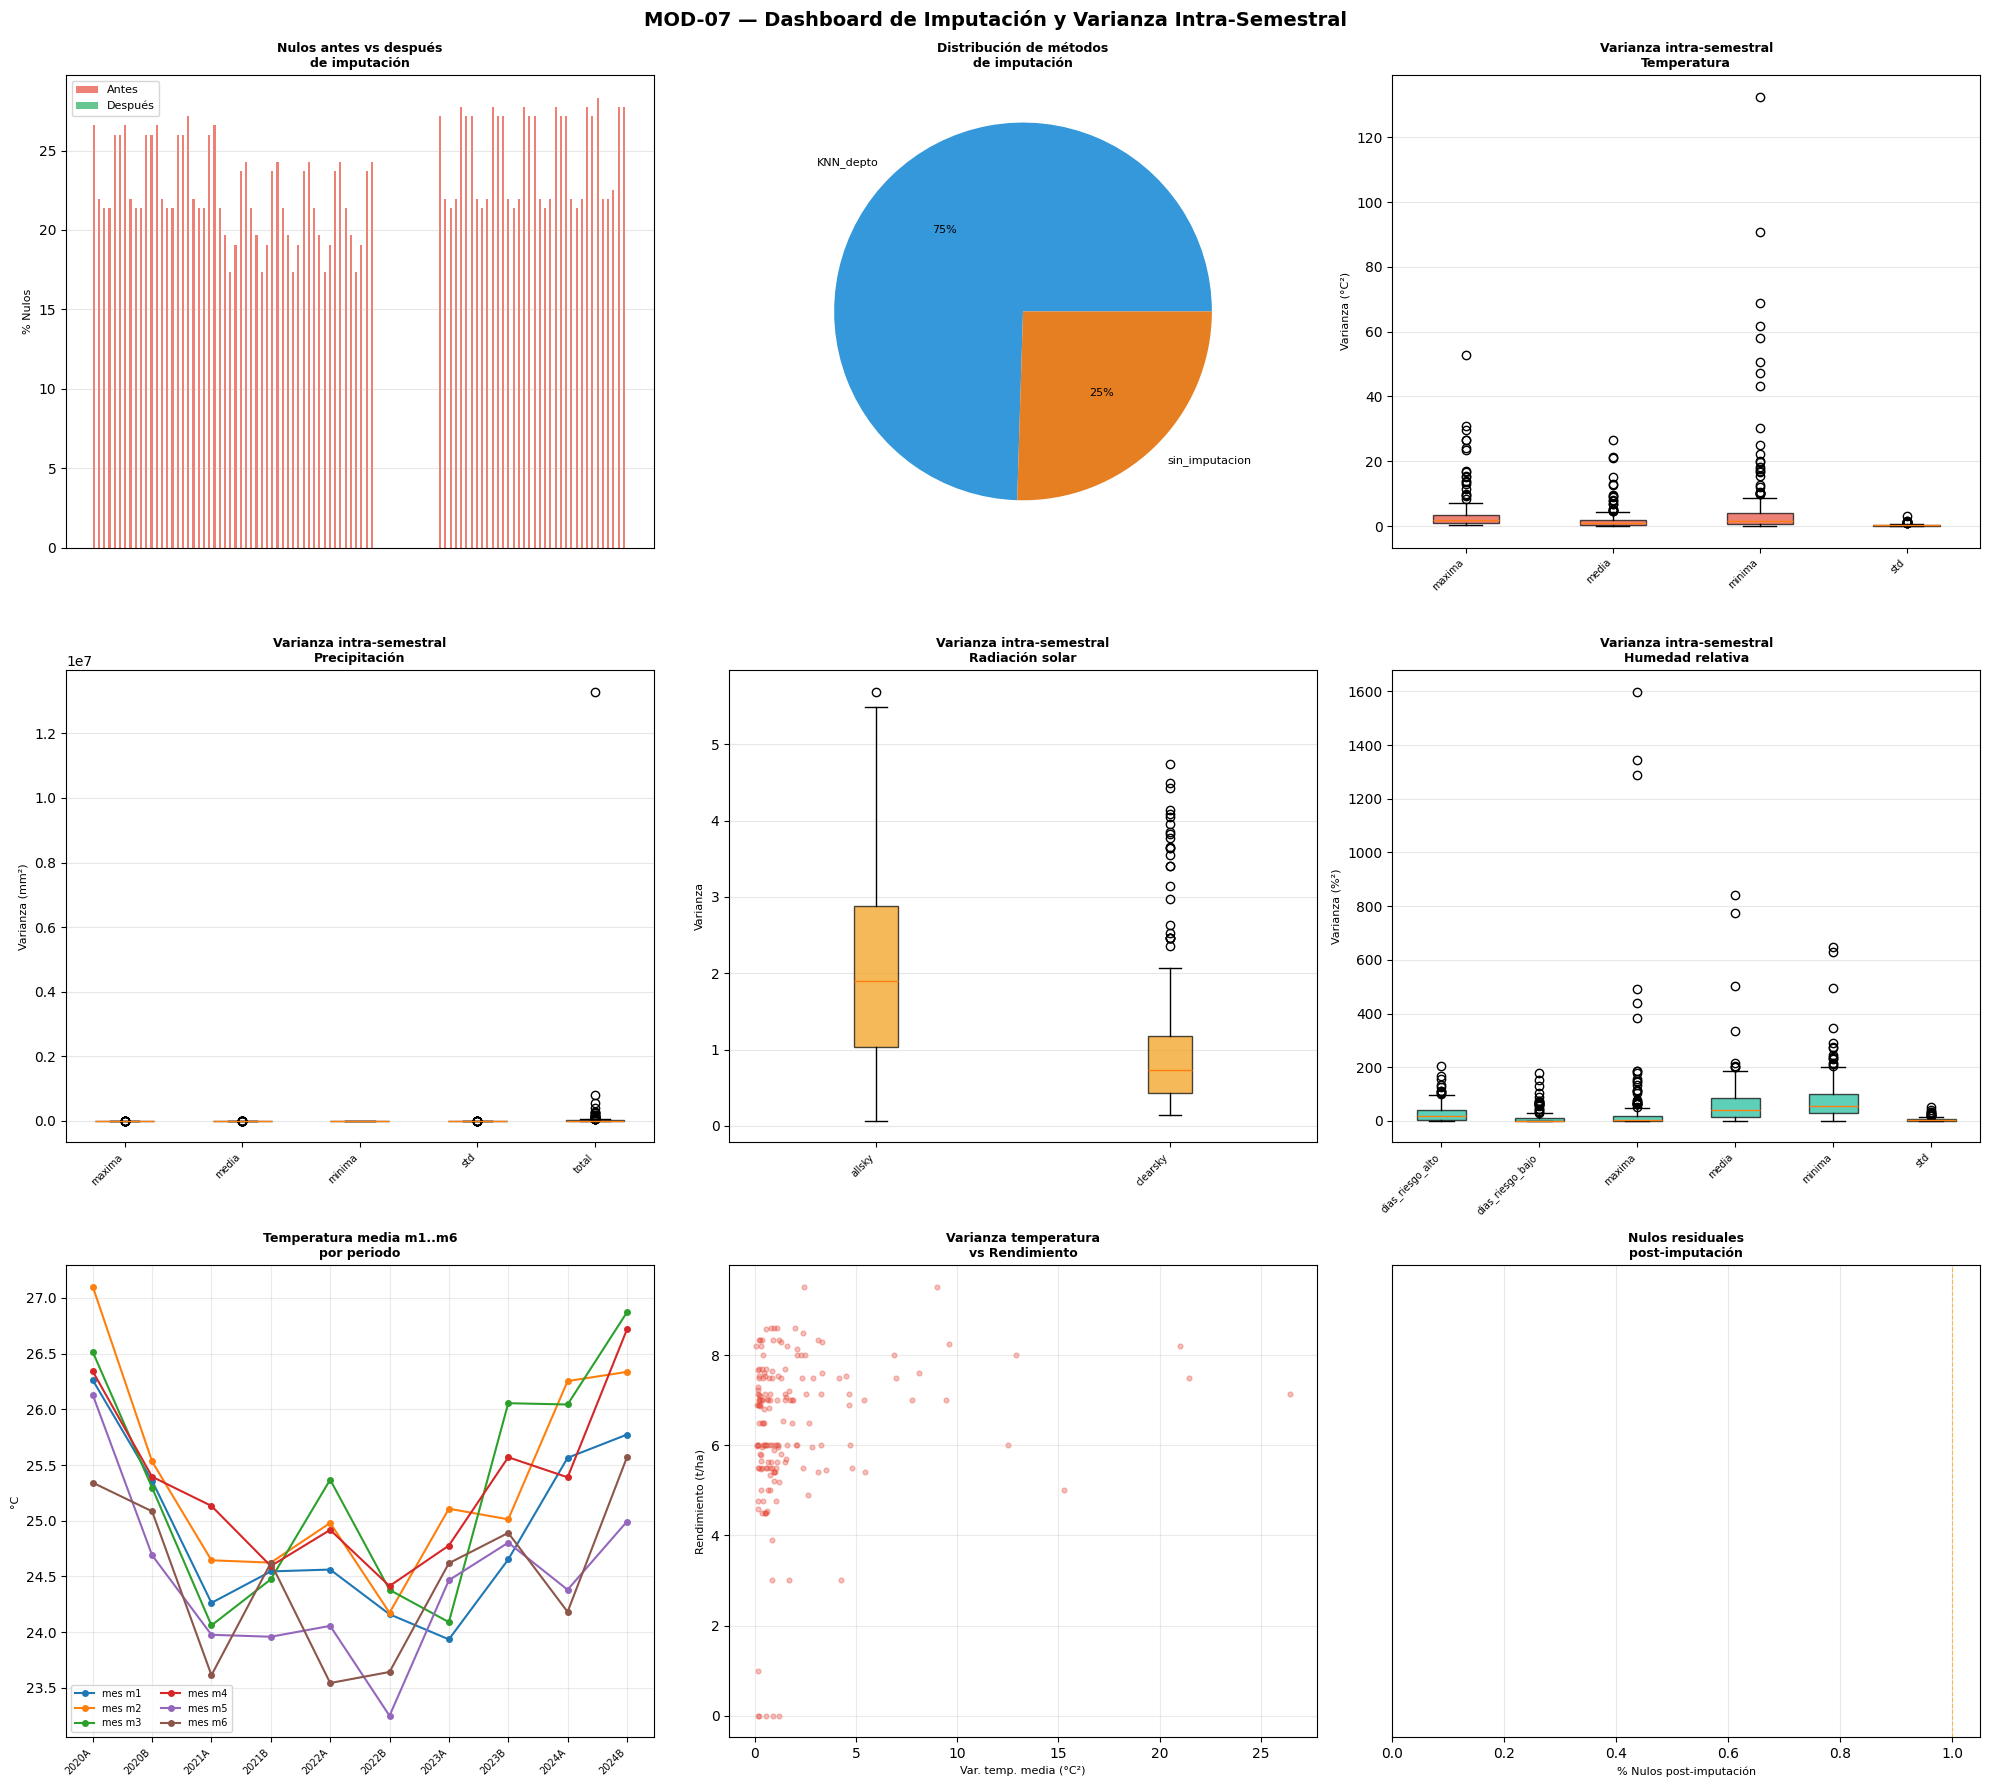

✅ Dashboard guardado: A2_Dashboard_Imputacion.png


In [10]:
# ============================================================
# DASHBOARD — Visualización de imputación y varianzas
# ============================================================

fig = plt.figure(figsize=(20, 18))
fig.suptitle(
    'MOD-07 — Dashboard de Imputación y Varianza Intra-Semestral',
    fontsize=14, fontweight='bold', y=0.99
)

# ── Panel 1: Nulos antes vs después ──────────────────────────
ax1 = fig.add_subplot(3, 3, 1)
cols_comp = [c for c in (COLS_TEMP_F + COLS_PREC_F + COLS_RAD_F + COLS_HR_F)
             if c in df_raw.columns and c in df_imputado.columns]
if cols_comp:
    pct_antes   = df_raw[cols_comp].isna().mean().mul(100)
    pct_despues = df_imputado[cols_comp].isna().mean().mul(100)
    x = range(len(cols_comp))
    ax1.bar(x, pct_antes.values,   width=0.4, label='Antes', color='#e74c3c', alpha=0.7)
    ax1.bar([i+0.4 for i in x], pct_despues.values,
            width=0.4, label='Después', color='#27ae60', alpha=0.7)
    ax1.set_xticks([])
    ax1.set_ylabel('% Nulos', fontsize=8)
    ax1.set_title('Nulos antes vs después\nde imputación', fontsize=9, fontweight='bold')
    ax1.legend(fontsize=8)
    ax1.grid(axis='y', alpha=0.3)

# ── Panel 2: Métodos usados (pastel) ─────────────────────────
ax2 = fig.add_subplot(3, 3, 2)
metodos = {}
for col, info in TRAZA_COMPLETA.items():
    m = info.get('metodo', 'sin_imputacion')
    metodos[m] = metodos.get(m, 0) + 1
if metodos:
    colores_m = ['#3498db','#e67e22','#2ecc71','#e74c3c','#9b59b6']
    ax2.pie(list(metodos.values()), labels=list(metodos.keys()),
            autopct='%1.0f%%', colors=colores_m[:len(metodos)],
            textprops={'fontsize':8})
    ax2.set_title('Distribución de métodos\nde imputación', fontsize=9, fontweight='bold')

# ── Panel 3: Boxplot varianzas de temperatura ────────────────
ax3 = fig.add_subplot(3, 3, 3)
if COLS_VAR_TEMP:
    data_v = [df_imputado[c].dropna().values for c in COLS_VAR_TEMP]
    bp = ax3.boxplot(data_v, patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#e74c3c'); patch.set_alpha(0.7)
    ax3.set_xticklabels([c.replace('temperatura_','').replace('_var','')
                         for c in COLS_VAR_TEMP], rotation=45, ha='right', fontsize=7)
    ax3.set_ylabel('Varianza (°C²)', fontsize=8)
    ax3.set_title('Varianza intra-semestral\nTemperatura', fontsize=9, fontweight='bold')
    ax3.grid(axis='y', alpha=0.3)

# ── Panel 4: Boxplot varianzas precipitación ─────────────────
ax4 = fig.add_subplot(3, 3, 4)
if COLS_VAR_PREC:
    data_v = [df_imputado[c].dropna().values for c in COLS_VAR_PREC]
    bp = ax4.boxplot(data_v, patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#3498db'); patch.set_alpha(0.7)
    ax4.set_xticklabels([c.replace('precipitacion_','').replace('_var','')
                         for c in COLS_VAR_PREC], rotation=45, ha='right', fontsize=7)
    ax4.set_ylabel('Varianza (mm²)', fontsize=8)
    ax4.set_title('Varianza intra-semestral\nPrecipitación', fontsize=9, fontweight='bold')
    ax4.grid(axis='y', alpha=0.3)

# ── Panel 5: Boxplot varianzas radiación ─────────────────────
ax5 = fig.add_subplot(3, 3, 5)
if COLS_VAR_RAD:
    data_v = [df_imputado[c].dropna().values for c in COLS_VAR_RAD]
    bp = ax5.boxplot(data_v, patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#f39c12'); patch.set_alpha(0.7)
    ax5.set_xticklabels([c.replace('radiacion_','').replace('_var','')
                         for c in COLS_VAR_RAD], rotation=45, ha='right', fontsize=7)
    ax5.set_ylabel('Varianza', fontsize=8)
    ax5.set_title('Varianza intra-semestral\nRadiación solar', fontsize=9, fontweight='bold')
    ax5.grid(axis='y', alpha=0.3)

# ── Panel 6: Boxplot varianzas humedad ───────────────────────
ax6 = fig.add_subplot(3, 3, 6)
if COLS_VAR_HR:
    data_v = [df_imputado[c].dropna().values for c in COLS_VAR_HR]
    bp = ax6.boxplot(data_v, patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#1abc9c'); patch.set_alpha(0.7)
    ax6.set_xticklabels([c.replace('hr_','').replace('_var','')
                         for c in COLS_VAR_HR], rotation=45, ha='right', fontsize=7)
    ax6.set_ylabel('Varianza (%²)', fontsize=8)
    ax6.set_title('Varianza intra-semestral\nHumedad relativa', fontsize=9, fontweight='bold')
    ax6.grid(axis='y', alpha=0.3)

# ── Panel 7: Evolución temperatura media m1..m6 por periodo ──
ax7 = fig.add_subplot(3, 3, 7)
cols_tm = sorted([c for c in COLS_TEMP_F if 'temperatura_media' in c])
if cols_tm and 'Periodo' in df_imputado.columns:
    evo = df_imputado.groupby('Periodo')[cols_tm].mean().reset_index()
    evo = evo.sort_values('Periodo')
    for col in cols_tm:
        lbl = col.replace('temperatura_media_', 'mes ')
        ax7.plot(range(len(evo)), evo[col], marker='o', ms=4, lw=1.5, label=lbl)
    ax7.set_xticks(range(len(evo)))
    ax7.set_xticklabels(evo['Periodo'], rotation=45, ha='right', fontsize=7)
    ax7.set_ylabel('°C', fontsize=8)
    ax7.set_title('Temperatura media m1..m6\npor periodo', fontsize=9, fontweight='bold')
    ax7.legend(fontsize=7, ncol=2)
    ax7.grid(alpha=0.25)

# ── Panel 8: Scatter varianza temp vs Rendimiento ────────────
ax8 = fig.add_subplot(3, 3, 8)
col_var_t  = next((c for c in COLS_VAR_TEMP if 'media' in c), None)
col_rend   = next((c for c in COLS_TARGET_FINAL if 'Rendimiento' in c or
                   'rendimiento' in c), None)
if col_var_t and col_rend and col_var_t in df_imputado.columns:
    sc = df_imputado[[col_var_t, col_rend]].dropna()
    ax8.scatter(sc[col_var_t], sc[col_rend], alpha=0.35, s=12, c='#e74c3c')
    ax8.set_xlabel(f'Var. temp. media (°C²)', fontsize=8)
    ax8.set_ylabel('Rendimiento (t/ha)', fontsize=8)
    ax8.set_title('Varianza temperatura\nvs Rendimiento', fontsize=9, fontweight='bold')
    ax8.grid(alpha=0.25)

# ── Panel 9: Mapa de nulos post-imputación ───────────────────
ax9 = fig.add_subplot(3, 3, 9)
cols_clima_final = (COLS_TEMP_F + COLS_PREC_F + COLS_RAD_F + COLS_HR_F)
cols_clima_pres  = [c for c in cols_clima_final if c in df_imputado.columns]
if cols_clima_pres:
    nulos_post = df_imputado[cols_clima_pres].isna().mean().mul(100)
    ax9.barh(range(len(nulos_post)), nulos_post.values,
             color=['#e74c3c' if v > 5 else '#27ae60' for v in nulos_post.values])
    ax9.set_yticks([])
    ax9.set_xlabel('% Nulos post-imputación', fontsize=8)
    ax9.set_title('Nulos residuales\npost-imputación', fontsize=9, fontweight='bold')
    ax9.axvline(1, color='orange', ls='--', lw=0.8, alpha=0.7)
    ax9.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RUTA_MASTER, 'A2_Dashboard_Imputacion.png'),
            dpi=130, bbox_inches='tight')
plt.show()
print('✅ Dashboard guardado: A2_Dashboard_Imputacion.png')


In [11]:
# ============================================================
# REPORTE DE IMPUTACIÓN Y GUARDAR SALIDAS
# ============================================================

# ── Reporte de trazabilidad ───────────────────────────────────
df_reporte = construir_reporte_imputacion(
    TRAZA_COMPLETA, df_raw, df_imputado, COLS_EXCLUIDAS
)

print('📋 Reporte de imputación (resumen):')
print(f'   {"Columna":<40}  {"Orig%":>6}  {"Final%":>6}  Método')
print(f'   {"-"*75}')
for _, row in df_reporte.iterrows():
    final_pct = (df_imputado[row["columna"]].isna().mean()*100
                 if row["columna"] in df_imputado.columns else 0)
    print(f'   {row["columna"]:<40}  {row["pct_orig"]:>5.1f}%  '
          f'{final_pct:>5.1f}%  {row["metodo"]}')

# Guardar reporte Excel
with pd.ExcelWriter(SALIDA_REPORTE_XLS, engine='openpyxl') as writer:
    df_reporte.to_excel(writer, sheet_name='Reporte_Imputacion', index=False)

    # Hoja de varianzas
    df_vars = pd.DataFrame({
        'variable_varianza' : VARS_CREADAS,
        'columnas_base'     : [
            ', '.join([f'{v}_m{n}' for n in range(1,7)
                       for v in [col.replace('_var','')]
                       if f'{v}_m{n}' in df_imputado.columns])
            for col in VARS_CREADAS
        ],
        'media_varianza' : [df_imputado[c].mean() if c in df_imputado.columns
                            else None for c in VARS_CREADAS],
        'nulos'          : [df_imputado[c].isna().sum() if c in df_imputado.columns
                            else None for c in VARS_CREADAS],
    })
    df_vars.to_excel(writer, sheet_name='Variables_Varianza', index=False)

print(f'\n✅ Reporte guardado: {SALIDA_REPORTE_XLS}')

# ── Guardar dataset imputado ──────────────────────────────────
print()
print('💾 Guardando A2_DF_Imputado...')
df_imputado.to_parquet(SALIDA_IMPUTADO, index=False,
                        engine='pyarrow', compression='snappy')
print(f'   ✅ Parquet → {SALIDA_IMPUTADO}')
print(f'      {df_imputado.shape[0]:,} filas × {df_imputado.shape[1]} cols')

MAX_EXCEL = 1_048_576
if df_imputado.shape[0] <= MAX_EXCEL:
    df_imputado.to_excel(SALIDA_IMPUTADO_XLS, index=False, engine='openpyxl')
    print(f'   ✅ Excel  → {SALIDA_IMPUTADO_XLS}')
else:
    df_imputado.head(MAX_EXCEL).to_excel(SALIDA_IMPUTADO_XLS, index=False,
                                          engine='openpyxl')
    print(f'   ⚠️  Excel truncado a {MAX_EXCEL:,} filas — usar Parquet en MOD-08')


📋 Reporte de imputación (resumen):
   Columna                                    Orig%  Final%  Método
   ---------------------------------------------------------------------------
   prec_minima_m4                            100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_minima_m3                            100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_minima_m2                            100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_minima_m1                            100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_dias_lluvia_m6                       100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_dias_lluvia_m5                       100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_dias_lluvia_m2                       100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_dias_lluvia_m1                       100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_pct_dias_lluvia_m5                   100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_pct_dias_lluvia_m6                   100.0%    0.0%  EXCLUIDA (

In [12]:
# ============================================================
# RESUMEN FINAL — MOD-07 completado
# ============================================================

sep = '='*65
print(sep)
print('  ✅ MOD-07 — Imputación y Control de Calidad  COMPLETADO')
print(sep)

print()
print('📦 Archivos generados:')
for archivo, desc in [
    ('A2_DF_Imputado.parquet',       f'{df_imputado.shape[0]:,} x {df_imputado.shape[1]} cols  ← usar en MOD-08'),
    ('A2_DF_Imputado.xlsx',          'inspección visual'),
    ('A2_Reporte_Imputacion.xlsx',   'trazabilidad de imputación + variables de varianza'),
    ('A2_Dashboard_Imputacion.png',  'dashboard 9 paneles'),
]:
    print(f'   📄 data/master/{archivo}')
    print(f'      {desc}')

print()
print('🔧 Métodos de imputación aplicados:')
print()
print('   1. KNN por Departamento (k=5)  — columnas con <= 50% nulos')
print('      Imputa con el promedio ponderado de los 5 vecinos más')
print('      similares dentro del mismo departamento.')
print('      Variables: temperatura, precipitación, radiación, humedad')
print()
print('   2. Mediana Global              — columnas con 50-80% nulos')
print('      Imputa con la mediana de todos los valores disponibles.')
print('      Robusto ante outliers estacionales.')
print()
print('   3. Eliminación de columna      — columnas con > 80% nulos')
print('      Se eliminan del dataset para no introducir sesgo.')
print()
print('   4. Exclusión total             — Ind_lluvia (prec_*)')
print('      100% nulos confirmados en MOD-06. Excluidas desde el inicio.')

print()
print('📐 Variables de varianza creadas:')
for bloque, pfx in BLOQUES.items():
    vars_bloque = [v for v in VARS_CREADAS if v.startswith(pfx)]
    if vars_bloque:
        print(f'   {bloque} ({len(vars_bloque)}):')
        for v in vars_bloque:
            base   = v.replace('_var', '')
            cols_b = [f'{base}_m{n}' for n in range(1,7)
                      if f'{base}_m{n}' in df_imputado.columns]
            print(f'     {v}  ←  {", ".join(cols_b)}')

print()
print('📊 Inventario final del dataset:')
print(f'   Filas         : {df_imputado.shape[0]:,}')
print(f'   Columnas      : {df_imputado.shape[1]}')
print(f'     Features clim.: {len(COLS_TEMP_F+COLS_PREC_F+COLS_RAD_F+COLS_HR_F)}')
print(f'     Varianzas     : {len(VARS_CREADAS)}')
print(f'     Objetivo      : {len(COLS_TARGET_FINAL)}')
print(f'   Nulos totales  : {df_imputado.isna().sum().sum():,} '
      f'({df_imputado.isna().mean().mean()*100:.2f}%)')

print()
print('➡️  Siguiente módulo : MOD-08 — Ingeniería de Variables')
print('    Entrada          : data/master/A2_DF_Imputado.parquet')
print(sep)

print()
print('Vista previa (3 filas):')
cols_prev = (['Periodo','Departamento','Municipio']
             + COLS_TARGET_FINAL[:1]
             + COLS_TEMP_F[:2] + COLS_VAR_TEMP[:1]
             + COLS_PREC_F[:2] + COLS_VAR_PREC[:1])
cols_prev = [c for c in cols_prev if c in df_imputado.columns]
display(df_imputado[cols_prev].head(3))


  ✅ MOD-07 — Imputación y Control de Calidad  COMPLETADO

📦 Archivos generados:
   📄 data/master/A2_DF_Imputado.parquet
      173 x 143 cols  ← usar en MOD-08
   📄 data/master/A2_DF_Imputado.xlsx
      inspección visual
   📄 data/master/A2_Reporte_Imputacion.xlsx
      trazabilidad de imputación + variables de varianza
   📄 data/master/A2_Dashboard_Imputacion.png
      dashboard 9 paneles

🔧 Métodos de imputación aplicados:

   1. KNN por Departamento (k=5)  — columnas con <= 50% nulos
      Imputa con el promedio ponderado de los 5 vecinos más
      similares dentro del mismo departamento.
      Variables: temperatura, precipitación, radiación, humedad

   2. Mediana Global              — columnas con 50-80% nulos
      Imputa con la mediana de todos los valores disponibles.
      Robusto ante outliers estacionales.

   3. Eliminación de columna      — columnas con > 80% nulos
      Se eliminan del dataset para no introducir sesgo.

   4. Exclusión total             — Ind_lluvia (prec

,Periodo,Departamento,Municipio,Área sembrada (ha),temperatura_maxima_m1,temperatura_maxima_m2,temperatura_maxima_var,precipitacion_maxima_m1,precipitacion_maxima_m2,precipitacion_maxima_var
0,2020A,CESAR,VALLEDUPAR,1717.0,39.200001,40.299999,0.561667,4.2,0.40,99.007996
1,2020B,CESAR,VALLEDUPAR,3420.0,39.099998,39.500000,4.747998,10.6,14.80,66.322861
2,2021A,CESAR,VALLEDUPAR,1643.0,36.700001,38.200001,0.369666,0.0,1.32,23.478666
